# What drives student exam scores?

**Data:** 1,000 students with math, reading and writing scores (0–100) plus gender, ethnic group (anonymised A–E), parents' education, lunch type (standard vs free/reduced, a proxy for family income) and whether they completed a test-preparation course.

**Questions**
1. Does the test-prep course make a real difference, and how big?
2. How large is the gap linked to family income (lunch type)?
3. Does parents' education matter?
4. Do boys and girls differ, and in which subjects?
5. Which factors matter most when considered together?

Differences are tested with Welch's t-test and sized with **Cohen's d** (0.2 small, 0.5 medium, 0.8 large), because with 1,000 students even tiny gaps become "significant".

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from common import style
from common.style import BLUE, ORANGE, AQUA, SERIES

style.apply()
df = pd.read_csv("data/students_performance.csv", encoding="utf-8-sig")
df.columns = ["gender", "group", "parent_education", "lunch", "test_prep", "math", "reading", "writing"]
SUBJECTS = ["math", "reading", "writing"]
df["average"] = df[SUBJECTS].mean(axis=1)
print(df.shape, "| missing:", df.isna().sum().sum(), "| duplicates:", df.duplicated().sum())
df.head()

(1000, 9) | missing: 0 | duplicates: 0


,gender,group,parent_education,lunch,test_prep,math,reading,writing,average
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667
1,female,group C,some college,standard,completed,69,90,88,82.333333
2,female,group B,master's degree,standard,none,90,95,93,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333
4,male,group C,some college,standard,none,76,78,75,76.333333


In [2]:
df[SUBJECTS + ["average"]].describe().round(1)

,math,reading,writing,average
count,1000.0,1000.0,1000.0,1000.0
mean,66.1,69.2,68.1,67.8
std,15.2,14.6,15.2,14.3
min,0.0,17.0,10.0,9.0
25%,57.0,59.0,57.8,58.3
50%,66.0,70.0,69.0,68.3
75%,77.0,79.0,79.0,77.7
max,100.0,100.0,100.0,100.0


## 1. Score distributions and how subjects relate

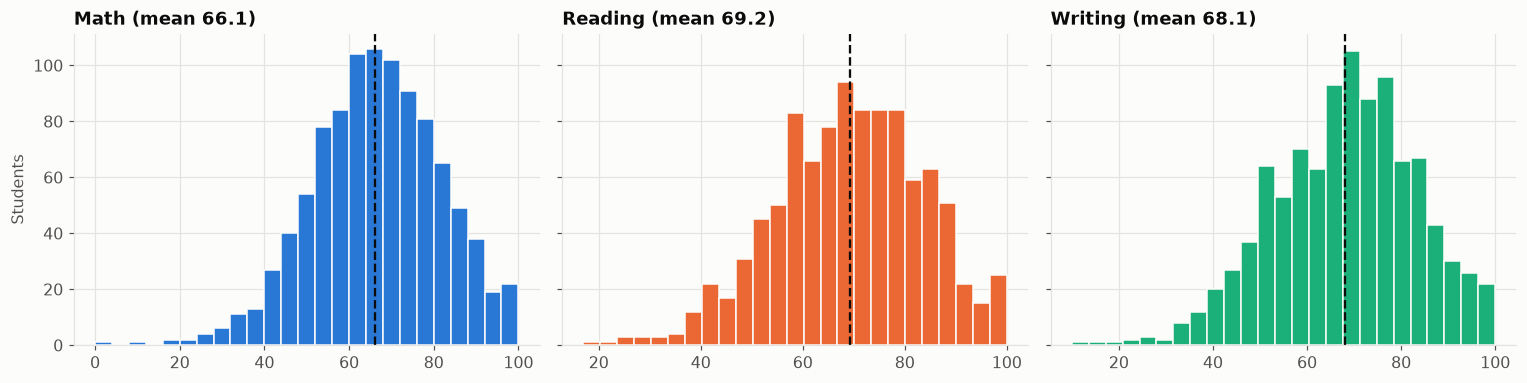

,math,reading,writing
math,1.00,0.82,0.80
reading,0.82,1.00,0.95
writing,0.80,0.95,1.00


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, subj, color in zip(axes, SUBJECTS, SERIES):
    ax.hist(df[subj], bins=25, color=color, edgecolor="#fcfcfb")
    ax.axvline(df[subj].mean(), color="#0b0b0b", ls="--", lw=1.5)
    ax.set_title(f"{subj.title()} (mean {df[subj].mean():.1f})", fontsize=11.5)
axes[0].set_ylabel("Students")
fig.tight_layout()
style.save(fig, "score_distributions")
plt.show()
df[SUBJECTS].corr().round(2)

Reading and writing are almost interchangeable (r ≈ 0.95); math is related but distinct (r ≈ 0.8). Strong students tend to be strong everywhere.

## 2–4. Group comparisons with effect sizes

In [4]:
def compare(col, a, b):
    """Welch t-test, Cohen's d and mean gap (a − b) for each subject."""
    rows = []
    for subj in SUBJECTS + ["average"]:
        x, y = df.loc[df[col] == a, subj], df.loc[df[col] == b, subj]
        t, p = stats.ttest_ind(x, y, equal_var=False)
        pooled = np.sqrt(((len(x) - 1) * x.var() + (len(y) - 1) * y.var()) / (len(x) + len(y) - 2))
        rows.append({"subject": subj, f"mean {a}": x.mean(), f"mean {b}": y.mean(),
                     "gap": x.mean() - y.mean(), "cohen_d": (x.mean() - y.mean()) / pooled, "p_value": p})
    out = pd.DataFrame(rows)
    num = out.columns.drop(["subject", "cohen_d", "p_value"])
    out[num] = out[num].round(1)
    out["cohen_d"] = out["cohen_d"].round(2)
    out["p_value"] = out["p_value"].map(lambda v: f"{v:.1e}")
    return out

prep = compare("test_prep", "completed", "none")
lunch = compare("lunch", "standard", "free/reduced")
gender = compare("gender", "female", "male")
print("Test-prep course: completed vs none"); display(prep)
print("Lunch: standard vs free/reduced"); display(lunch)
print("Gender: female vs male"); display(gender)

Test-prep course: completed vs none


,subject,mean completed,mean none,gap,cohen_d,p_value
0,math,69.7,64.1,5.6,0.38,1.0e-08
1,reading,73.9,66.5,7.4,0.52,4.4e-15
2,writing,74.4,64.5,9.9,0.69,2.7e-25
3,average,72.7,65.0,7.6,0.55,4.4e-17


Lunch: standard vs free/reduced


,subject,mean standard,mean free/reduced,gap,cohen_d,p_value
0,math,70.0,58.9,11.1,0.78,5.5e-28
1,reading,71.7,64.7,7.0,0.49,8.4e-13
2,writing,70.8,63.0,7.8,0.53,1.7e-14
3,average,70.8,62.2,8.6,0.63,1.6e-19


Gender: female vs male


,subject,mean female,mean male,gap,cohen_d,p_value
0,math,63.6,68.7,-5.1,-0.34,8.4e-08
1,reading,72.6,65.5,7.1,0.50,4.4e-15
2,writing,72.5,63.3,9.2,0.63,1.7e-22
3,average,69.6,65.8,3.7,0.26,3.2e-05


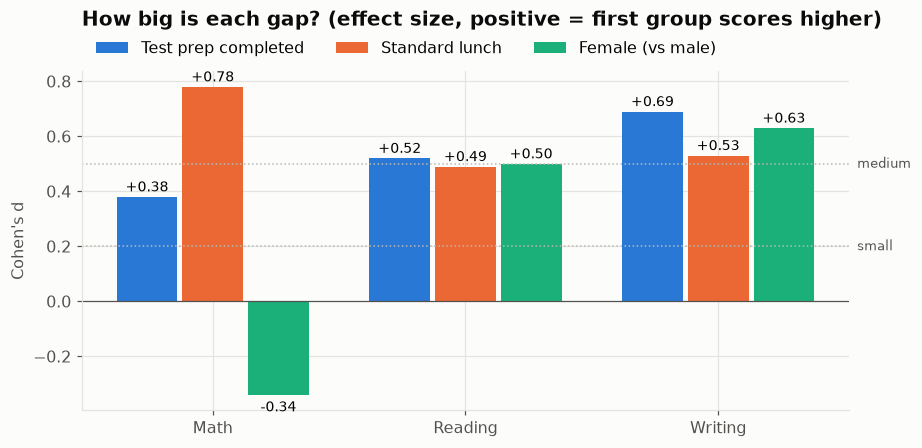

In [5]:
effects = pd.DataFrame({
    "Test prep completed": prep.set_index("subject")["cohen_d"],
    "Standard lunch": lunch.set_index("subject")["cohen_d"],
    "Female (vs male)": gender.set_index("subject")["cohen_d"],
}).loc[SUBJECTS]

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(SUBJECTS))
w = 0.26
for i, (name, color) in enumerate(zip(effects.columns, SERIES)):
    vals = effects[name].values
    ax.bar(x + (i - 1) * w, vals, w - 0.02, color=color, label=name)
    for xi, v in zip(x + (i - 1) * w, vals):
        ax.text(xi, v + (0.02 if v >= 0 else -0.06), f"{v:+.2f}", ha="center", fontsize=9)
ax.axhline(0, color="#52514e", lw=0.8)
for level, lab in [(0.2, "small"), (0.5, "medium")]:
    ax.axhline(level, color="#b9b8b2", ls=":", lw=1)
    ax.text(2.55, level, lab, fontsize=8.5, color="#52514e", va="center")
ax.set_xticks(x, [s.title() for s in SUBJECTS])
ax.set_ylabel("Cohen's d")
ax.set_title("How big is each gap? (effect size, positive = first group scores higher)", pad=30)
ax.legend(loc="lower left", ncols=3, bbox_to_anchor=(0, 1.0))
style.save(fig, "effect_sizes")
plt.show()

## 3. Parents' education

,count,mean
parent_education,,
some high school,179,65.1
high school,196,63.1
some college,226,68.5
associate's degree,222,69.6
bachelor's degree,118,71.9
master's degree,59,73.6


ANOVA F = 10.8, p = 4.4e-10, eta² = 0.051 (share of score variance explained by parents' education)


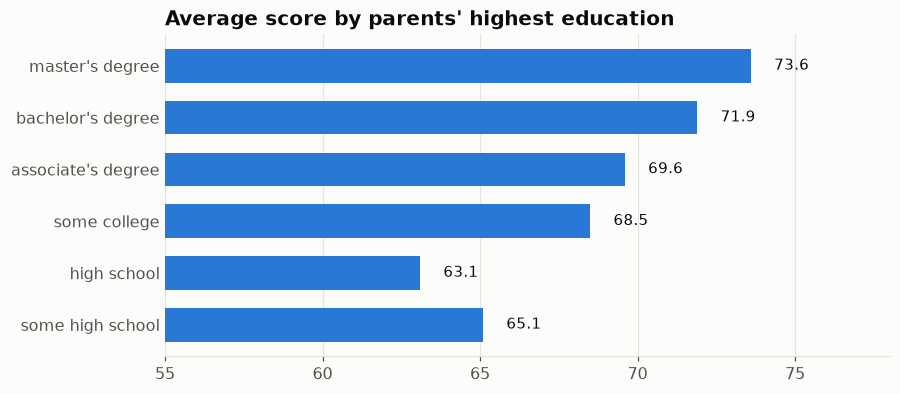

In [6]:
order = ["some high school", "high school", "some college", "associate's degree", "bachelor's degree", "master's degree"]
by_parent = df.groupby("parent_education")["average"].agg(["count", "mean"]).reindex(order).round(1)
f, p_anova = stats.f_oneway(*[df.loc[df["parent_education"] == lvl, "average"] for lvl in order])
eta_sq = by_parent["count"].mul((by_parent["mean"] - df["average"].mean()) ** 2).sum() / ((df["average"] - df["average"].mean()) ** 2).sum()
display(by_parent)
print(f"ANOVA F = {f:.1f}, p = {p_anova:.1e}, eta² = {eta_sq:.3f} (share of score variance explained by parents' education)")

fig, ax = plt.subplots(figsize=(8.5, 3.8))
style.hbar(ax, by_parent.index[::-1], by_parent["mean"][::-1], fmt="{:.1f}")
ax.set_xlim(55, 78)
ax.set_title("Average score by parents' highest education")
style.save(fig, "parent_education")
plt.show()

## 5. All factors together

A linear regression of the **average score** on all five factors at once. Each coefficient is the score difference vs the reference group *holding the other factors fixed*.

In [7]:
X = pd.get_dummies(df[["gender", "group", "parent_education", "lunch", "test_prep"]], drop_first=False)
reference = ["gender_male", "group_group A", "parent_education_some high school", "lunch_free/reduced", "test_prep_none"]
X = X.drop(columns=reference).astype(float)
reg = LinearRegression().fit(X, df["average"])
coefs = pd.Series(reg.coef_, index=X.columns).sort_values()
print(f"R² = {reg.score(X, df['average']):.3f}: these 5 background factors explain about "
      f"{100 * reg.score(X, df['average']):.0f}% of the variation in average score.")
coefs.round(2).to_frame("points vs reference")

R² = 0.242: these 5 background factors explain about 24% of the variation in average score.


,points vs reference
parent_education_high school,-0.63
group_group B,1.53
group_group C,2.39
parent_education_some college,3.61
gender_female,3.72
parent_education_associate's degree,4.54
group_group D,5.13
group_group E,6.93
parent_education_bachelor's degree,7.08
test_prep_completed,7.64


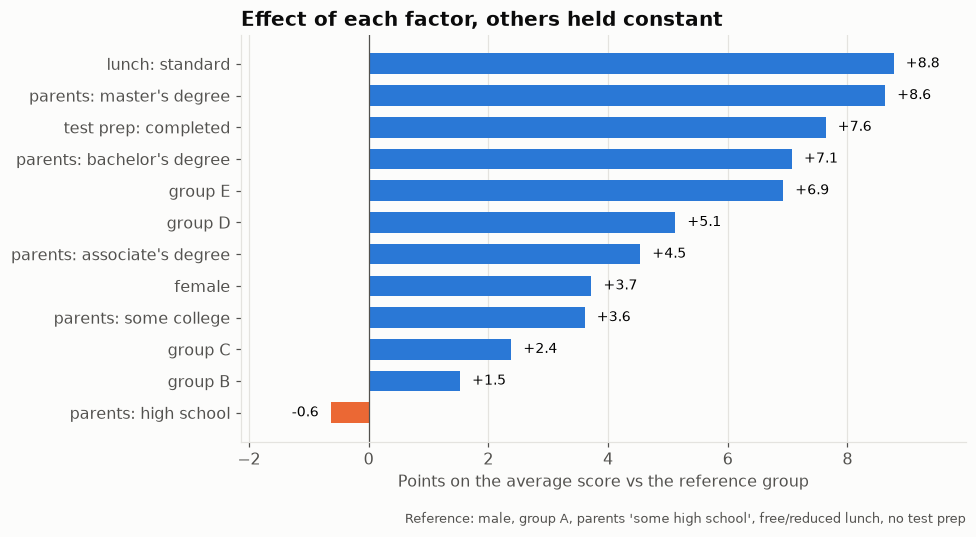

In [8]:
nice = (coefs.rename(lambda c: c.replace("parent_education_", "parents: ").replace("group_", "")
                     .replace("lunch_", "lunch: ").replace("test_prep_", "test prep: ").replace("gender_", ""))
        .sort_values())
fig, ax = plt.subplots(figsize=(8.5, 4.8))
colors = [ORANGE if v < 0 else BLUE for v in nice.values]
ax.barh(nice.index, nice.values, color=colors, height=0.65)
for i, v in enumerate(nice.values):
    ax.text(v + (0.2 if v >= 0 else -0.2), i, f"{v:+.1f}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_xlabel("Points on the average score vs the reference group")
ax.set_title("Effect of each factor, others held constant")
ax.set_xlim(nice.min() - 1.5, nice.max() + 1.2)
ax.text(1, -0.2, "Reference: male, group A, parents 'some high school', free/reduced lunch, no test prep",
        transform=ax.transAxes, ha="right", fontsize=8.5, color="#52514e")
ax.grid(axis="y", visible=False)
style.save(fig, "regression_effects")
plt.show()

## Key findings

In [9]:
pd_ = prep.set_index("subject"); ld = lunch.set_index("subject"); gd = gender.set_index("subject")
print(f"1. Free/reduced lunch (lower family income) is the biggest single gap: {abs(ld.loc['average', 'gap']):.1f} points "
      f"on average, largest in math ({abs(ld.loc['math', 'gap']):.1f} points, d = {ld.loc['math', 'cohen_d']:.2f}).")
print(f"2. Completing the test-prep course goes with +{pd_.loc['average', 'gap']:.1f} points on average "
      f"(d = {pd_.loc['average', 'cohen_d']:.2f}); the effect is biggest for writing (+{pd_.loc['writing', 'gap']:.1f}) "
      f"and smallest for math (+{pd_.loc['math', 'gap']:.1f}).")
print(f"3. Gender gaps run in opposite directions: girls lead in reading (+{gd.loc['reading', 'gap']:.1f}) and writing "
      f"(+{gd.loc['writing', 'gap']:.1f}), medium effects (d = {gd.loc['reading', 'cohen_d']:.2f}, {gd.loc['writing', 'cohen_d']:.2f}); "
      f"boys lead in math by {-gd.loc['math', 'gap']:.1f} points, a smaller effect (d = {-gd.loc['math', 'cohen_d']:.2f}).")
print(f"4. Parents' education matters but explains only {100 * eta_sq:.0f}% of score variance: from "
      f"{by_parent['mean'].iloc[0]:.1f} (some high school) to {by_parent['mean'].iloc[-1]:.1f} (master's degree).")
print(f"5. Together the five background factors explain only {100 * reg.score(X, df['average']):.0f}% of the variation: "
      "most of what separates students is not in this data (effort, prior attainment, school, etc.).")
print("Caveat: this is observational data. Students who took the prep course may differ in other ways, "
      "so the gaps are associations, not proof of cause.")

1. Free/reduced lunch (lower family income) is the biggest single gap: 8.6 points on average, largest in math (11.1 points, d = 0.78).
2. Completing the test-prep course goes with +7.6 points on average (d = 0.55); the effect is biggest for writing (+9.9) and smallest for math (+5.6).
3. Gender gaps run in opposite directions: girls lead in reading (+7.1) and writing (+9.2), medium effects (d = 0.50, 0.63); boys lead in math by 5.1 points, a smaller effect (d = 0.34).
4. Parents' education matters but explains only 5% of score variance: from 65.1 (some high school) to 73.6 (master's degree).
5. Together the five background factors explain only 24% of the variation: most of what separates students is not in this data (effort, prior attainment, school, etc.).
Caveat: this is observational data. Students who took the prep course may differ in other ways, so the gaps are associations, not proof of cause.
